<a href="https://colab.research.google.com/github/Abdoulaye279/Financial-Engineering/blob/main/var-es-sp500/08_yearly_weights.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 08 - Out-of-sample risk weights: yearly, then monthly with DCC

In 07 the equal-risk weights were computed on the whole 2004-2026 period, so they knew the future. Here only past data is used:
- yearly: equal share of the historical ES over the last 1000 days, set each January
- monthly, sample: risk parity on the covariance of the last 250 days, set each month
- monthly, DCC: risk parity on the next-day covariance forecast of GARCH + DCC (refitted every 250 days on 1000 days)

Same seven assets as 07. Takes ~1 min.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Financial-Engineering
    %cd Financial-Engineering/var-es-sp500
except ImportError:
    pass

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from risk import *
plt.style.use("quant.mplstyle")

assets = ["spx", "aapl", "msft", "jpm", "xom", "gld", "tlt"]
prices = pd.concat({a: load_close("../black-scholes-sp500/data/sp500.csv" if a == "spx" else f"data/{a}.csv") for a in assets},
                   axis=1).dropna()
rets = np.log(prices).diff().dropna()
simple = np.exp(rets) - 1

first year: 2009-01-02
       spx  aapl  msft   jpm   xom   gld   tlt
Date                                          
2009  0.05  0.05  0.06  0.05  0.05  0.15  0.59
2010  0.06  0.07  0.07  0.04  0.06  0.19  0.51
2011  0.06  0.07  0.07  0.04  0.06  0.19  0.51
2012  0.07  0.08  0.07  0.04  0.06  0.19  0.50
2013  0.10  0.11  0.10  0.04  0.14  0.20  0.33
2014  0.10  0.08  0.10  0.08  0.12  0.10  0.42
2015  0.11  0.08  0.12  0.08  0.10  0.10  0.41
2016  0.11  0.09  0.10  0.10  0.09  0.13  0.37
2017  0.11  0.09  0.09  0.11  0.09  0.15  0.35
2018  0.11  0.10  0.08  0.10  0.09  0.26  0.26
2019  0.08  0.08  0.07  0.09  0.08  0.27  0.33
2020  0.09  0.07  0.07  0.10  0.08  0.23  0.35
2021  0.07  0.07  0.07  0.06  0.06  0.18  0.49
2022  0.07  0.07  0.07  0.06  0.06  0.20  0.47
2023  0.08  0.07  0.07  0.07  0.07  0.22  0.41
2024  0.08  0.07  0.07  0.07  0.07  0.22  0.41
2025  0.10  0.09  0.08  0.12  0.11  0.23  0.26
2026  0.09  0.07  0.08  0.09  0.09  0.27  0.31


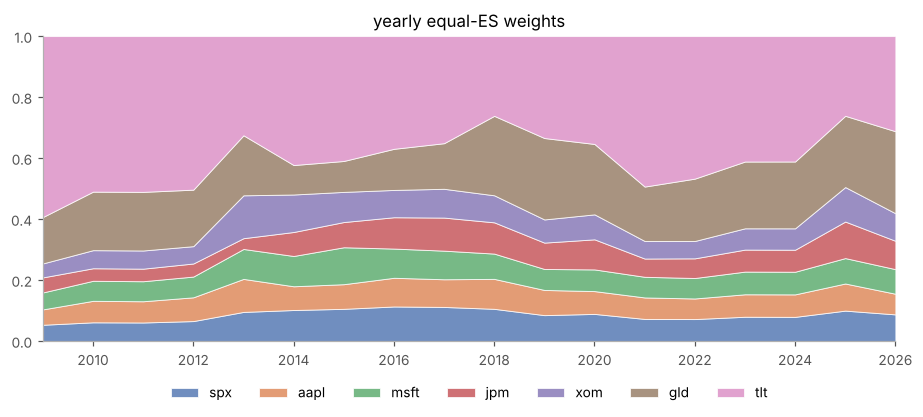

In [3]:
W_year = rolling_equal_risk_weights(simple, window=1000)
start = W_year.dropna().index[0]
yearly = W_year.dropna().groupby(W_year.dropna().index.year).first()
print("first year:", start.date())
print(yearly.round(2))

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.stackplot(yearly.index, yearly.T.values, labels=assets, alpha=0.8, edgecolor="white", linewidth=0.6)
ax.set_xlim(yearly.index[0], yearly.index[-1]); ax.set_ylim(0, 1); ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=7); ax.set_title("yearly equal-ES weights")
plt.show()
# bonds take 26-59% of the money, gold 10-27%, each stock 4-12%
# january 2022: bonds still 47%, the window is 2018-2021 when they went up on the bad days
# after that the bond weight comes down slowly (41% in 2023-24, 26% in 2025): 4 years of memory

In [4]:
W_sample = monthly_risk_parity(rets, method="sample", cov_days=250)
W_dcc = monthly_risk_parity(rets, method="dcc", window=1000, refit=250)
W_full = pd.DataFrame([equal_risk_weights(simple.values)] * len(simple), index=simple.index, columns=assets)   # look-ahead (07)

S = simple.loc[start:]
strategies = {"S&P 500": None, "1/7": None, "yearly ES": W_year, "monthly sample": W_sample, "monthly DCC": W_dcc,
              "full period (look-ahead)": W_full}

def turnover(W):
    ch = W.loc[start:].diff().abs().sum(axis=1)
    return ch.sum() / ((S.index[-1] - S.index[0]).days / 365.25)

perf = {}
for nm, W in strategies.items():
    p = S.spx if nm == "S&P 500" else S @ np.full(7, 1 / 7) if nm == "1/7" else (S * W.loc[start:]).sum(axis=1)
    perf[nm] = np.log1p(p)
    wealth = np.exp(perf[nm].cumsum()); dd = wealth / wealth.cummax() - 1
    v, e = var_es_hist(perf[nm].values)
    to = 0 if W is None else turnover(W)
    print(f"{nm:24s} return {252 * perf[nm].mean():5.1%}  vol {np.sqrt(252) * perf[nm].std():5.1%}  ES {e:.2%}  "
          f"max dd {dd.min():6.1%} ({dd.idxmin().date()})  2022 {np.expm1(perf[nm].loc['2022'].sum()):6.1%}  turnover/yr {to:.2f}")
# yearly ES: out of sample 2.26% vs 2.09% with hindsight, hindsight matters little. but -17.2% in 2022
# monthly with a 1-year covariance already gets 2022 down to -11.2%; DCC -10.5%, the best ES (2.14%) and return
# DCC trades a lot more (1.69 of the portfolio per year vs 0.43): ~0.17%/yr at 10bp per trade, below its edge
# turnover here only counts the changes of target weights, not the daily rebalancing back to them (same for all)

S&P 500                  return 11.6%  vol 17.9%  ES 4.68%  max dd -33.9% (2020-03-23)  2022 -19.4%  turnover/yr 0.00
1/7                      return 14.8%  vol 14.3%  ES 3.51%  max dd -25.9% (2020-03-23)  2022  -7.9%  turnover/yr 0.00
yearly ES                return  9.7%  vol  9.8%  ES 2.26%  max dd -22.6% (2022-10-20)  2022 -17.2%  turnover/yr 0.14
monthly sample           return 10.6%  vol  9.7%  ES 2.34%  max dd -18.8% (2022-09-30)  2022 -11.2%  turnover/yr 0.43
monthly DCC              return 11.7%  vol  9.5%  ES 2.14%  max dd -18.7% (2022-09-27)  2022 -10.5%  turnover/yr 1.69
full period (look-ahead) return  9.6%  vol  9.5%  ES 2.09%  max dd -21.3% (2022-10-20)  2022 -16.1%  turnover/yr 0.00


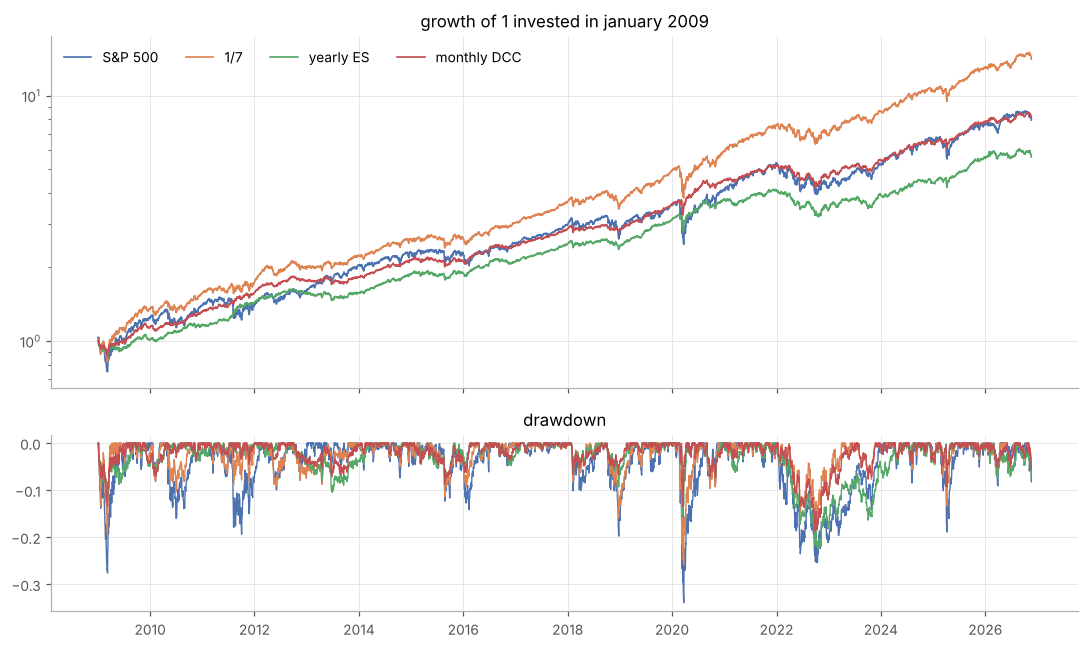

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for nm in ["S&P 500", "1/7", "yearly ES", "monthly DCC"]:
    wealth = np.exp(perf[nm].cumsum())
    ax[0].plot(wealth, label=nm)
    ax[1].plot(wealth / wealth.cummax() - 1, lw=0.9, label=nm)
ax[0].set_yscale("log"); ax[0].set_title("growth of 1 invested in january 2009"); ax[0].legend(ncol=4)
ax[1].set_title("drawdown")
plt.tight_layout(); plt.show()
# 1/7 and the S&P: worst moment march 2020. the risk-weighted portfolios barely dip there but fall in 2022
# monthly DCC is above yearly ES almost all the way and ends level with the S&P 500 (11.7% vs 11.6% a year)
# with about half of its volatility

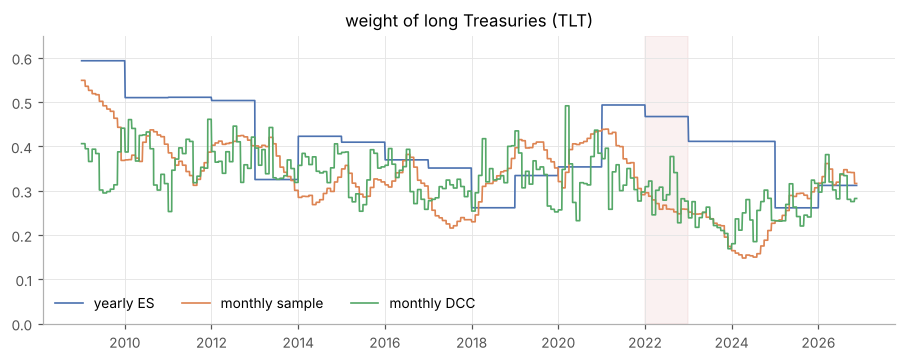

TLT weight on the first day of each quarter, 2022:
            yearly ES  monthly sample  monthly DCC
Date                                              
2022-01-01       0.47            0.30         0.31
2022-04-01       0.47            0.27         0.30
2022-07-01       0.47            0.26         0.29
2022-10-01       0.47            0.25         0.23


In [6]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(W_year["tlt"].loc[start:], label="yearly ES")
ax.plot(W_sample["tlt"].loc[start:], label="monthly sample")
ax.plot(W_dcc["tlt"].loc[start:], label="monthly DCC")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"), color="#c44e52", alpha=0.08)
ax.set_title("weight of long Treasuries (TLT)"); ax.set_ylim(0, 0.65); ax.legend(ncol=3)
plt.show()
print("TLT weight on the first day of each quarter, 2022:")
print(pd.DataFrame({k: W["tlt"].loc["2022"].resample("QS").first() for k, W in
                    [("yearly ES", W_year), ("monthly sample", W_sample), ("monthly DCC", W_dcc)]}).round(2))
# in january 2022 the yearly ES weights put 47% in bonds, the two covariance versions ~30%
# part of the 2022 gap is the risk measure: the ES rewards an asset that went up on the crash days of the window,
# the variance doesn't give that credit. the rest is speed: DCC cuts bonds from 29% to 23% between july and october

In [7]:
print("share of the ES in 2022 (average weights of 2022):")
for nm, W in [("yearly ES", W_year), ("monthly DCC", W_dcc)]:
    print(f"  {nm:12s}", dict(zip(assets, es_contributions(S.loc["2022"].values, W.loc["2022"].mean().values).round(2))))
# yearly: bonds brought half of the 2022 risk instead of 1/7. with DCC 21%, closer to the target

share of the ES in 2022 (average weights of 2022):
  yearly ES    {'spx': np.float64(0.08), 'aapl': np.float64(0.11), 'msft': np.float64(0.09), 'jpm': np.float64(0.04), 'xom': np.float64(0.07), 'gld': np.float64(0.12), 'tlt': np.float64(0.5)}
  monthly DCC  {'spx': np.float64(0.13), 'aapl': np.float64(0.14), 'msft': np.float64(0.14), 'jpm': np.float64(0.13), 'xom': np.float64(0.11), 'gld': np.float64(0.14), 'tlt': np.float64(0.21)}
